# Practical 3: Image Classification using CNN (MNIST)

Run the cells from top to bottom. Use ONE dataset loading option in Step 2.


In [1]:
# 1. Import packages (same as the reference notebook)
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# 2. Load MNIST dataset - use ONE option

# OPTION 1: Directly from Keras (ACTIVE, same as reference)
# First run may download MNIST; future runs use the Keras cache.
(train_x, train_y), (test_x, test_y) = mnist.load_data()

# OPTION 2: MNIST .npz file in the same folder (OFFLINE)
# Comment Option 1 and uncomment all lines below.
# data = np.load("mnist.npz")
# train_x, train_y = data["x_train"], data["y_train"]
# test_x, test_y = data["x_test"], data["y_test"]

# OPTION 3: MNIST .csv files in the same folder (OFFLINE)
# Each CSV: first column = label, next 784 columns = pixel values.
# Comment Option 1 and uncomment all lines below.
# import pandas as pd
# train = pd.read_csv("mnist_train.csv")  # add header=None if no header row
# test = pd.read_csv("mnist_test.csv")    # add header=None if no header row
# train_y = train.iloc[:, 0].to_numpy()
# train_x = train.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)
# test_y = test.iloc[:, 0].to_numpy()
# test_x = test.iloc[:, 1:].to_numpy().reshape(-1, 28, 28)

In [3]:
# Step 3: Display dataset shapes
print("X_train:", train_x.shape)
print("Y_train:", train_y.shape)
print("X_test:", test_x.shape)
print("Y_test:", test_y.shape)


X_train: (60000, 28, 28)
Y_train: (60000,)
X_test: (10000, 28, 28)
Y_test: (10000,)


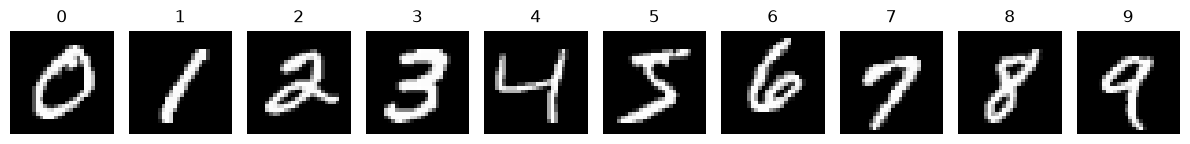

In [4]:
# Step 4: Display digits 0 to 9
plt.figure(figsize=(12, 3))
for digit in range(10):
    index = np.where(train_y == digit)[0][0]
    plt.subplot(1, 10, digit + 1)
    plt.imshow(train_x[index], cmap="gray")
    plt.title(str(digit))
    plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
# Step 5: Normalize and reshape for CNN
train_x = train_x.reshape(-1, 28, 28, 1) / 255.0
test_x = test_x.reshape(-1, 28, 28, 1) / 255.0


In [6]:
# Step 6: Build CNN model
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])


In [7]:
# Step 7: Compile model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


In [8]:
# Step 8: Train model
history = model.fit(train_x, train_y, epochs=3, validation_split=0.1)


Epoch 1/3


   1/1688 ━━━━━━━━━━━━━━━━━━━━ 22:26 798ms/step - accuracy: 0.0312 - loss: 2.3429

  14/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4241 - loss: 2.0480     

  26/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5373 - loss: 1.7696

  39/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6106 - loss: 1.4987

  51/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6593 - loss: 1.3028

... (578 outputs left out)

1667/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9819 - loss: 0.0621

1677/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9819 - loss: 0.0622

1687/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9818 - loss: 0.0622

1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9819 - loss: 0.0622 - val_accuracy: 0.9830 - val_loss: 0.0597


In [9]:
# Step 9: Evaluate accuracy
loss, accuracy = model.evaluate(test_x, test_y)
print("Test Accuracy:", accuracy)


  1/313 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.9688 - loss: 0.1347

 21/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9851 - loss: 0.0516 

 39/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9760 - loss: 0.0836

 60/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9750 - loss: 0.0843

 78/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9732 - loss: 0.0879

 98/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9739 - loss: 0.0870

... (9 outputs left out)

292/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9827 - loss: 0.0565

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9828 - loss: 0.0572

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9828 - loss: 0.0572


Test Accuracy: 0.9828000068664551


Actual Digit: 7
Predicted Digit: 7


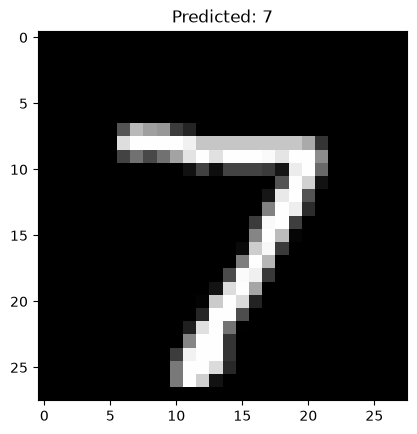

In [10]:
# Step 10: Predict and display one image
prediction = model.predict(test_x[:1], verbose=0)
predicted_digit = np.argmax(prediction)
print("Actual Digit:", test_y[0])
print("Predicted Digit:", predicted_digit)
plt.imshow(test_x[0].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {predicted_digit}")
plt.show()


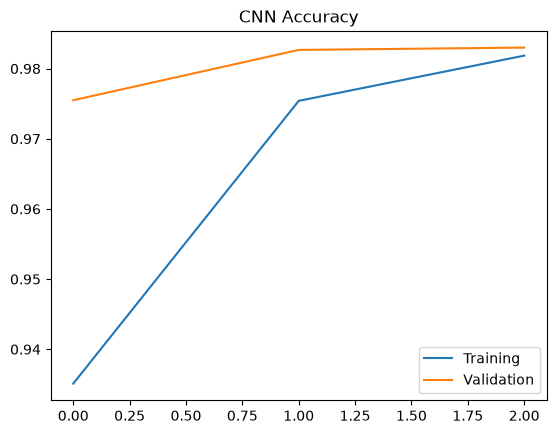

In [11]:
# Step 11: Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()
plt.show()
